In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
tmdb = pd.read_csv('data/tmdb_1.csv')
div = pd.read_csv('data/oscars_diversity.csv')

print(f"Movie database shape: {tmdb.shape}\nDiversity dataset shape: {div.shape}")

Movie database shape: (152686, 24)
Diversity dataset shape: (10396, 9)


## Research Question 2:
### Does racial/ gender diversity affect the number of awards that a movie wins?


First I want to filter the datasets to the colums that I will use for my analysis, and merge them into one usable dataset.

In [2]:
tmdb = tmdb[['title','release_date','genres','status']]

In [3]:
movie_div = pd.merge(tmdb, div, how='left', left_on = 'title', right_on= 'film')
movie_div.head()


,title,release_date,genres,status,year_film,year_ceremony,ceremony,Category,gender,name,Race,film,winner
0,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,PRODUCTION DESIGN,Male,Production Design: Guy Hendrix Dyas; Set Decor...,White,Inception,False
1,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,CINEMATOGRAPHY,Male,Wally Pfister,White,Inception,True
2,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,MUSIC (Original Score),Male,Hans Zimmer,White,Inception,False
3,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,BEST PICTURE,Female,"Emma Thomas and Christopher Nolan, Producers",White,Inception,False
4,Inception,2010-07-15,"Action, Science Fiction, Adventure",Released,2010.0,2011.0,83.0,SOUND EDITING,Male,Richard King,White,Inception,True


In [4]:
movie_div['release_date'] = pd.to_datetime(movie_div['release_date'])

Since the Screen Actors Guild was founded in 1933, I will only use data from then onward, as the lack of POC data might affect the analysis. To do this, I will convert the release date column into a datetime object instead of a string

In [5]:
movie_div = movie_div[(movie_div['release_date'] >= '1930-06-30') & (movie_div['winner'] == True)]

Now I want to see both the racial distribution of winners, as well as gender

gender
Male      2533
Female     691
Name: count, dtype: int64

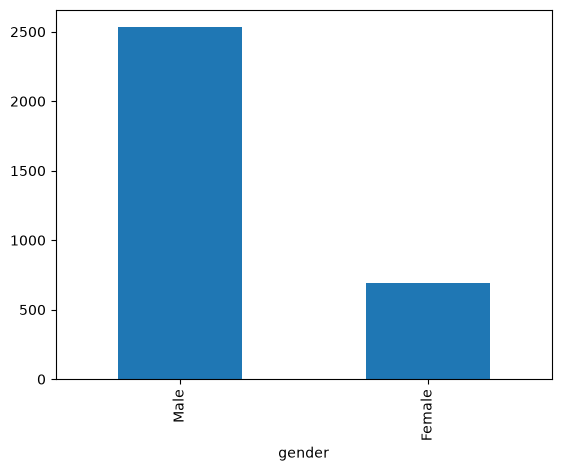

In [7]:
movie_div['gender'] = movie_div['gender'].str.capitalize()
movie_gender_wins = movie_div['gender'].value_counts()
movie_gender_wins.plot(kind="bar")

movie_div['gender'].value_counts()

Race
White       3070
Asian         75
Black         65
Hispanic      14
Name: count, dtype: int64

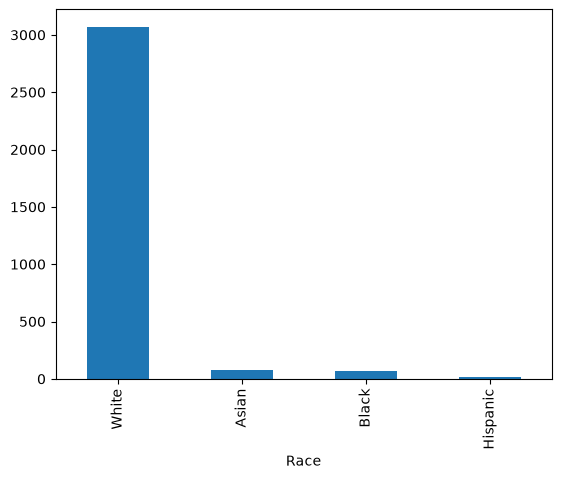

In [19]:
movie_race = movie_div['Race'].value_counts()
movie_race.plot(kind = "bar")

movie_div['Race'].value_counts()

Since the creation of the Screen Actors Guild, far more male winners have been elected than female winners, with 2533 wins. In the case of race, there have been far more white winners, with a total of 3070